In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import yaml

# 1. Cargar configuración
with open("../config/config.yaml", "r", encoding="utf-8") as file:
    config = yaml.safe_load(file)

carpeta_gold = "../" + config["path"]["gold_dir"]

# 2. Cargar los tres Data Marts
df_pais = pd.read_csv(os.path.join(carpeta_gold, "gold_resumen_pais.csv"))
df_peligro = pd.read_csv(os.path.join(carpeta_gold, "gold_matriz_peligro.csv"))
df_continente = pd.read_csv(os.path.join(carpeta_gold, "gold_resumen_continente.csv"))

print("Data Marts cargados exitosamente. ¡Listos para visualizar!")

Data Marts cargados exitosamente. ¡Listos para visualizar!


--- 1. RANKING DE PAÍSES (AQI PROMEDIO) ---


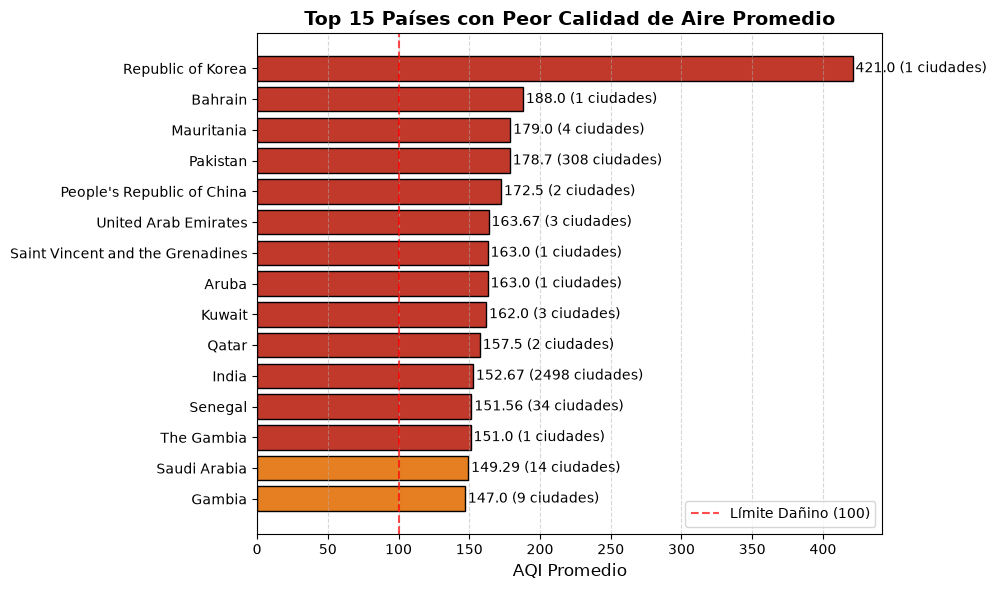

In [2]:
print("--- 1. RANKING DE PAÍSES (AQI PROMEDIO) ---")

# Tomamos los 15 peores (ya vienen ordenados del script load)
top_15_paises = df_pais.head(15).copy()
top_15_paises = top_15_paises.sort_values('aqi_promedio', ascending=True) # Invertir para que el peor quede arriba en el gráfico

plt.figure(figsize=(10, 6))

# Lógica condicional de colores basada en el valor AQI
colores = ['#c0392b' if val > 150 else '#e67e22' if val > 100 else '#f1c40f' for val in top_15_paises['aqi_promedio']]

barras = plt.barh(top_15_paises['country'], top_15_paises['aqi_promedio'], color=colores, edgecolor='black')

plt.title("Top 15 Países con Peor Calidad de Aire Promedio", fontsize=14, fontweight='bold')
plt.xlabel("AQI Promedio", fontsize=12)
plt.axvline(x=100, color='red', linestyle='--', alpha=0.7, label='Límite Dañino (100)')
plt.legend()
plt.grid(axis='x', linestyle='--', alpha=0.5)

# Añadir el número exacto y la cantidad de ciudades analizadas al lado de cada barra
for barra, ciudades in zip(barras, top_15_paises['total_ciudades']):
    ancho = barra.get_width()
    plt.text(ancho + 2, barra.get_y() + barra.get_height()/2, 
             f"{ancho} ({ciudades} ciudades)", 
             va='center', fontsize=10)

plt.tight_layout()
plt.show()

--- 2. COMPOSICIÓN DEL RIESGO EN PAÍSES CON MAYOR CANTIDAD DE MEDICIONES ---


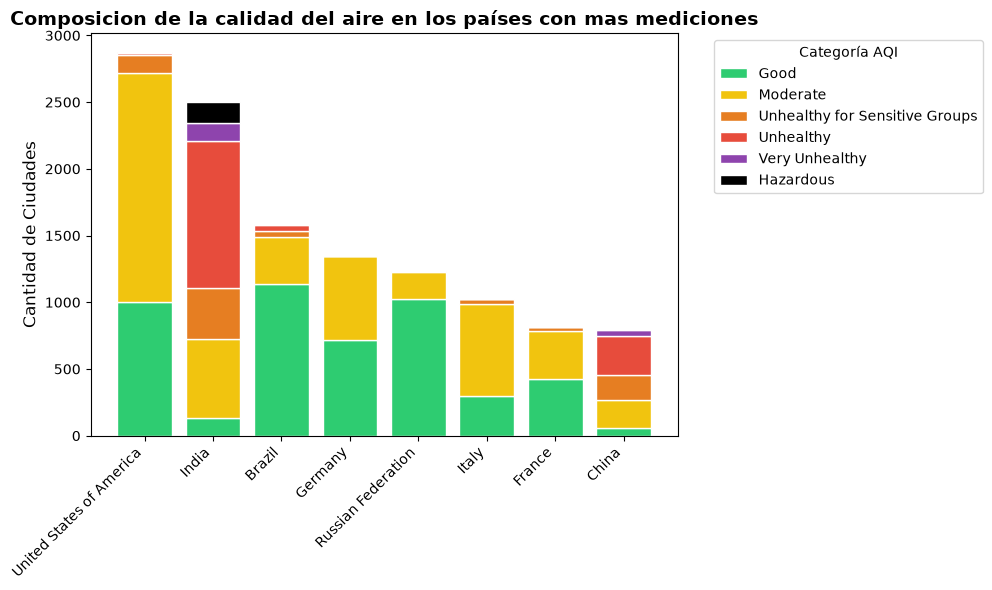

In [ ]:
print("--- 2. COMPOSICIÓN DEL RIESGO EN PAÍSES CON MAYOR CANTIDAD DE MEDICIONES ---")

# Unimos con df_pais para saber cuáles son los países con más ciudades registradas
df_peligro_completo = pd.merge(df_peligro, df_pais[['country', 'total_ciudades']], on='country')
top_8_volumen = df_peligro_completo.sort_values('total_ciudades', ascending=False).head(8)

paises = top_8_volumen['country'].values

# Extraemos las categorías (verificamos cuáles existen en las columnas)
categorias_posibles = ['Good', 'Moderate', 'Unhealthy for Sensitive Groups', 'Unhealthy', 'Very Unhealthy', 'Hazardous']
categorias_presentes = [cat for cat in categorias_posibles if cat in top_8_volumen.columns]

# Colores fijos para cada categoría
colores_cat = {'Good': '#2ecc71', 'Moderate': '#f1c40f', 'Unhealthy for Sensitive Groups': '#e67e22', 
               'Unhealthy': '#e74c3c', 'Very Unhealthy': '#8e44ad', 'Hazardous': '#000000'}

fig, ax = plt.subplots(figsize=(10, 6))
bottom = np.zeros(len(paises))

for cat in categorias_presentes:
    valores = top_8_volumen[cat].fillna(0).values
    ax.bar(paises, valores, bottom=bottom, label=cat, color=colores_cat[cat], edgecolor='white')
    bottom += valores

ax.set_title("Composicion de la calidad del aire en los paises con mas mediciones", fontsize=14, fontweight='bold')
ax.set_ylabel("Cantidad de Ciudades", fontsize=12)
ax.legend(title="Categoría AQI", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

--- 3. RADIOGRAFÍA MACRO-CONTINENTAL DE QUÍMICOS ---


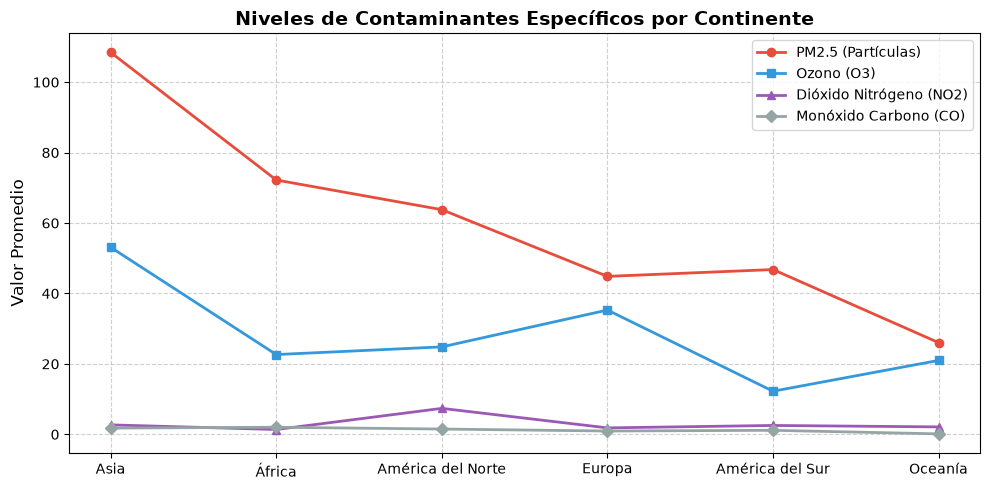

In [ ]:
print("--- 3. RADIOGRAFÍA MACRO-CONTINENTAL DE QUÍMICOS ---")

plt.figure(figsize=(10, 5))

# Variables a graficar
continentes = df_continente['continente']
pm25 = df_continente['pm25_promedio']
ozono = df_continente['ozono_promedio']
co = df_continente['co_promedio']
no2 = df_continente['no2_promedio']

# Graficamos líneas con marcadores para ver la tendencia
plt.plot(continentes, pm25, marker='o', linewidth=2, color='#e74c3c', label='PM2.5 (Partículas)')
plt.plot(continentes, ozono, marker='s', linewidth=2, color='#3498db', label='Ozono (O3)')
plt.plot(continentes, no2, marker='^', linewidth=2, color='#9b59b6', label='Dióxido Nitrógeno (NO2)')
plt.plot(continentes, co, marker='D', linewidth=2, color='#95a5a6', label='Monóxido Carbono (CO)')

plt.title("Niveles de contaminantes especificos por continente", fontsize=14, fontweight='bold')
plt.ylabel("Valor Promedio", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()